<a href="https://colab.research.google.com/github/Abdullah-567/Deep-Learning-Tutorials/blob/main/Tutorial_6_Pretrained_Models_Top5_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 6 — Predicting Top-5 Labels with Pretrained Models (PyTorch, complete with all tasks)

| Part | Content |
|---|---|
| **0** | Setup, config, data pipeline, model/training helpers |
| **1** | Top-5 predictions with pretrained VGG16 / ResNet50 (Steps 1–6 ported from Keras) |
| **2** | Task: experiment with AlexNet, ResNet101, MobileNet |
| **3** | Task: transfer learning on a downloaded dataset (CIFAR-10) with all architectures |
| **4** | Final comparison + conclusions |

**How to run:** Google Colab -> *Runtime -> Change runtime type -> GPU (T4)* -> *Run all*.
On CPU the notebook automatically switches to a tiny "quick run" so it still finishes (accuracy will be low).

## Part 0 — Setup

In [ ]:
# Colab already has everything. Uncomment if you run locally:
# !pip install -q torch torchvision matplotlib pandas pillow

In [ ]:
import os, time, random, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, models, transforms

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"          # mixed precision = faster on GPU
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)

# ------------------------------------------------------------------ run size
QUICK_RUN = DEVICE.type == "cpu"         # tiny subset on CPU; set to False to force the full run
N_TRAIN = 4000  if QUICK_RUN else 45000  # (max 45000: 5000 images are held out for validation)
N_VAL   = 1000  if QUICK_RUN else 5000
N_TEST  = 1000  if QUICK_RUN else 10000

BATCH_SIZE        = 64
IMG_SIZE_IMPROVED = 64                   # 224 gives the best accuracy but is ~12x slower
EPOCHS_BASE = 3  if QUICK_RUN else 10    # tutorial value = 10
EPOCHS_LONG = 6  if QUICK_RUN else 25
EPOCHS_TL   = 2  if QUICK_RUN else 5     # epochs per run in Part 3
NUM_WORKERS = 2
print("QUICK_RUN =", QUICK_RUN, "| train/val/test =", N_TRAIN, N_VAL, N_TEST)

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device: cuda
QUICK_RUN = False | train/val/test = 45000 5000 10000


### Data pipeline
*Baseline* (= the tutorial): 32×32 images, pixels scaled to [0, 1] (`ToTensor`).
*Improved*: resize, ImageNet mean/std normalisation (what the pretrained weights expect), optional augmentation.

100%|██████████| 170M/170M [38:00<00:00, 74.8kB/s]


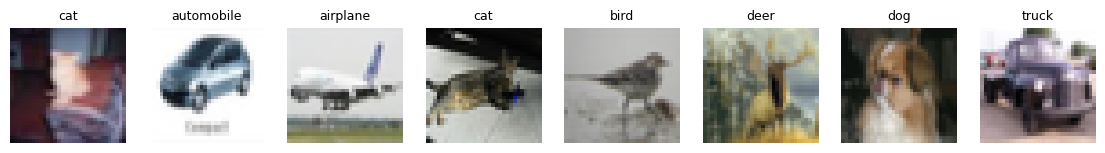

In [ ]:
DATA_DIR = "./data"
CLASSES = ('airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck')
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

# Download once (CIFAR-10, ~170 MB)
datasets.CIFAR10(DATA_DIR, train=True,  download=True)
datasets.CIFAR10(DATA_DIR, train=False, download=True)

# Fixed split -> every experiment sees exactly the same images
_perm     = np.random.RandomState(SEED).permutation(50000)
VAL_IDX   = _perm[:N_VAL]
TRAIN_IDX = _perm[5000:5000 + N_TRAIN]
TEST_IDX  = np.random.RandomState(SEED).permutation(10000)[:N_TEST]

def make_transforms(img_size=32, norm="none", augment=False):
    tr, ev = [], []
    if img_size != 32:
        tr.append(transforms.Resize(img_size)); ev.append(transforms.Resize(img_size))
    if augment:
        tr += [transforms.RandomHorizontalFlip(), transforms.RandomCrop(img_size, padding=img_size // 8)]
    tr.append(transforms.ToTensor()); ev.append(transforms.ToTensor())
    if norm == "imagenet":
        n = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
        tr.append(n); ev.append(n)
    return transforms.Compose(tr), transforms.Compose(ev)

def get_loaders(img_size=32, norm="none", augment=False, batch_size=BATCH_SIZE):
    tr_t, ev_t = make_transforms(img_size, norm, augment)
    tr_full = datasets.CIFAR10(DATA_DIR, train=True,  download=False, transform=tr_t)
    ev_full = datasets.CIFAR10(DATA_DIR, train=True,  download=False, transform=ev_t)
    te_full = datasets.CIFAR10(DATA_DIR, train=False, download=False, transform=ev_t)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0)
    train_loader = DataLoader(Subset(tr_full, TRAIN_IDX), batch_size=batch_size, shuffle=True, drop_last=True, **kw)
    val_loader   = DataLoader(Subset(ev_full, VAL_IDX),   batch_size=256, shuffle=False, **kw)
    test_loader  = DataLoader(Subset(te_full, TEST_IDX),  batch_size=256, shuffle=False, **kw)
    return train_loader, val_loader, test_loader

# quick look at the data
raw = datasets.CIFAR10(DATA_DIR, train=True, download=False)
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, i in zip(axes, TRAIN_IDX[:8]):
    ax.imshow(raw[i][0]); ax.set_title(CLASSES[raw[i][1]], fontsize=9); ax.axis("off")
plt.show()

### Models
* `build_model(arch, ...)` loads an **ImageNet-pretrained** torchvision model and swaps its classifier for the tutorial's head:
  `Flatten → Dense(512, ReLU) → Dense(10)` (plus optional dropout / a deeper BN head for the improvement task).
* `configure_trainable(model, unfreeze)`:  `0` = **feature extraction** (only the new head trains),
  `N` = **fine-tuning** (head + last *N* conv/BN layers), `"all"` = full fine-tuning.
* `CustomCNN` = small network trained **from scratch** (for the comparison in Part 3).

In [ ]:
def make_head(in_features, hidden=512, dropout=0.0, n_classes=10, head_type="simple"):
    if head_type == "simple":        # tutorial: Dense(512, relu) -> Dense(10)
        return nn.Sequential(nn.Linear(in_features, hidden), nn.ReLU(inplace=True),
                             nn.Dropout(dropout), nn.Linear(hidden, n_classes))
    if head_type == "bn_deep":       # "different layers": deeper head with BatchNorm
        return nn.Sequential(nn.Linear(in_features, 1024), nn.BatchNorm1d(1024), nn.ReLU(inplace=True), nn.Dropout(dropout),
                             nn.Linear(1024, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True), nn.Dropout(dropout),
                             nn.Linear(256, n_classes))
    raise ValueError(head_type)

# arch -> (name of the classifier attribute, #features entering it)
ARCH_INFO = {"vgg16": ("classifier", 512), "alexnet": ("classifier", 256),
             "resnet50": ("fc", 2048), "resnet101": ("fc", 2048), "mobilenet_v2": ("classifier", 1280)}

def build_model(arch, pretrained=True, dropout=0.0, head_type="simple"):
    model = models.get_model(arch, weights="IMAGENET1K_V1" if pretrained else None)
    attr, in_f = ARCH_INFO[arch]
    if arch in ("vgg16", "alexnet"):
        model.avgpool = nn.AdaptiveAvgPool2d(1)      # like Keras Flatten on the last conv map (works for any input size)
    setattr(model, attr, make_head(in_f, dropout=dropout, head_type=head_type))
    model._head_attr = attr
    return model

class CustomCNN(nn.Module):
    """Small VGG-style CNN trained from scratch."""
    def __init__(self, n_classes=10, dropout=0.0):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.classifier = make_head(128, dropout=dropout)
        self._head_attr = "classifier"
    def forward(self, x):
        return self.classifier(self.features(x))

def head_of(model):
    return getattr(model, model._head_attr)

def backbone_layers(model):
    """Leaf layers that own parameters (conv / BN / linear), in forward order, excluding the new head."""
    head_ids = {id(m) for m in head_of(model).modules()}
    return [m for m in model.modules()
            if not list(m.children()) and list(m.parameters(recurse=False)) and id(m) not in head_ids]

def configure_trainable(model, unfreeze=0):
    for p in model.parameters(): p.requires_grad = False
    for p in head_of(model).parameters(): p.requires_grad = True
    layers = backbone_layers(model)
    chosen = layers if unfreeze == "all" else (layers[-unfreeze:] if unfreeze else [])
    for m in chosen:
        for p in m.parameters(): p.requires_grad = True

def set_train_mode(model):
    """model.train(), but BatchNorm layers whose weights are frozen stay in eval mode."""
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            ps = list(m.parameters(recurse=False))
            if ps and not any(p.requires_grad for p in ps):
                m.eval()

def trainable_param_groups(model, lr_head, lr_backbone):
    head_ids = {id(p) for p in head_of(model).parameters()}
    head_p = [p for p in model.parameters() if id(p) in head_ids]
    bb_p   = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [{"params": head_p, "lr": lr_head}]
    if bb_p: groups.append({"params": bb_p, "lr": lr_backbone})
    return groups

# sanity check: how many layers does each strategy train?
_m = build_model("resnet50", pretrained=False)
for n in (0, 5, 20, 58, "all"):
    configure_trainable(_m, n)
    print(f"ResNet50 unfreeze={n!s:>3}: trainable params = {sum(p.numel() for p in _m.parameters() if p.requires_grad):>11,}")
del _m

ResNet50 unfreeze=  0: trainable params =   1,054,218
ResNet50 unfreeze=  5: trainable params =   4,468,234
ResNet50 unfreeze= 20: trainable params =  16,018,954
ResNet50 unfreeze= 58: trainable params =  23,117,322
ResNet50 unfreeze=all: trainable params =  24,562,250


### Training / evaluation helpers (with early stopping, LR scheduler, label smoothing, AMP)

In [ ]:
def evaluate(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    tot, correct, n = 0.0, 0, 0
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            out = model(x).float()
            tot += crit(out, y).item(); correct += (out.argmax(1) == y).sum().item(); n += y.numel()
    return tot / n, correct / n

def fit(model, train_loader, val_loader, cfg):
    model.to(DEVICE)
    opt  = torch.optim.AdamW(trainable_param_groups(model, cfg["lr_head"], cfg["lr_backbone"]),
                             weight_decay=cfg["weight_decay"])
    sched = None
    if cfg["scheduler"] == "cosine":
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"] * len(train_loader))
    crit   = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val, best_state, bad = -1.0, None, 0

    for epoch in range(1, cfg["epochs"] + 1):
        set_train_mode(model)
        t0, run_loss, correct, n = time.time(), 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(x).float()
                loss = crit(out, y)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            if sched: sched.step()
            run_loss += loss.item() * y.size(0); correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
        vl, va = evaluate(model, val_loader)
        hist["train_loss"].append(run_loss / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(vl);             hist["val_acc"].append(va)
        print(f"  epoch {epoch:>2}/{cfg['epochs']}  train loss {run_loss/n:.3f} acc {correct/n:.3f} | "
              f"val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
        if cfg["patience"]:                                   # early stopping on validation accuracy
            if va > best_val + 1e-4:
                best_val, bad = va, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= cfg["patience"]:
                    print(f"  early stopping at epoch {epoch} (best val acc {best_val:.3f})"); break
    if best_state is not None:
        model.load_state_dict(best_state)                     # restore best weights
    return hist

# Default recipe = the Keras tutorial (Adam 1e-3, 32x32 pixels in [0,1], no augmentation, no regularisation)
BASE_CFG = dict(img_size=32, norm="none", augment=False, dropout=0.0, head_type="simple",
                epochs=EPOCHS_BASE, lr_head=1e-3, lr_backbone=1e-3, weight_decay=0.0,
                label_smoothing=0.0, scheduler=None, patience=None, unfreeze=5)

RESULTS, BEST = [], {"acc": -1.0}

def run_experiment(name, arch, mode, **overrides):
    """mode: 'fe' = feature extraction | 'ft' = fine-tuning (last cfg['unfreeze'] layers) | 'scratch' = custom CNN"""
    cfg = {**BASE_CFG, **overrides}
    set_seed()
    print(f"\n=== {name}  [{arch} | {mode} | {cfg['img_size']}px | unfreeze={cfg['unfreeze'] if mode=='ft' else '-'} | "
          f"lr {cfg['lr_head']:g}/{cfg['lr_backbone']:g} | epochs {cfg['epochs']}]")
    train_loader, val_loader, test_loader = get_loaders(cfg["img_size"], cfg["norm"], cfg["augment"])
    if mode == "scratch":
        model = CustomCNN(dropout=cfg["dropout"])
    else:
        model = build_model(arch, True, cfg["dropout"], cfg["head_type"])
        configure_trainable(model, cfg["unfreeze"] if mode == "ft" else 0)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    t0 = time.time()
    hist = fit(model, train_loader, val_loader, cfg)
    secs = time.time() - t0
    test_loss, test_acc = evaluate(model, test_loader)
    print(f"  >> {name} Test Accuracy: {test_acc * 100:.2f}%  (trainable params {trainable:,}, {secs:.0f}s)")
    res = dict(name=name, arch=arch, mode=mode, img_size=cfg["img_size"], epochs_run=len(hist["val_acc"]),
               trainable_params=trainable, best_val_acc=max(hist["val_acc"]), test_acc=test_acc,
               test_loss=test_loss, train_time_s=secs, history=hist)
    RESULTS.append(res)
    if test_acc > BEST["acc"]:                                # keep the best model for the prediction demo at the end
        BEST.update(acc=test_acc, name=name, cfg=cfg, model=model.cpu())
    else:
        del model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return res

def plot_histories(results, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for i, r in enumerate(results):
        h, c = r["history"], f"C{i}"
        ep = range(1, len(h["val_acc"]) + 1)
        ax[0].plot(ep, h["train_acc"], "--", color=c, alpha=.6); ax[0].plot(ep, h["val_acc"], color=c, label=r["name"])
        ax[1].plot(ep, h["train_loss"], "--", color=c, alpha=.6); ax[1].plot(ep, h["val_loss"], color=c)
    ax[0].set_title("Accuracy (dashed = train, solid = validation)"); ax[1].set_title("Loss (dashed = train, solid = validation)")
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()

def results_table(results):
    cols = ["name", "arch", "mode", "img_size", "epochs_run", "trainable_params", "best_val_acc", "test_acc", "train_time_s"]
    df = pd.DataFrame([{c: r[c] for c in cols} for r in results])
    df["test_acc"] = (df["test_acc"] * 100).round(2); df["best_val_acc"] = (df["best_val_acc"] * 100).round(2)
    df["train_time_s"] = df["train_time_s"].round(0).astype(int)
    return df

## Part 1 — Tutorial 6: Predicting the top-5 labels with pretrained models

Pretrained ImageNet classifiers (1000 classes). Each torchvision weight set ships its own preprocessing (`weights.transforms()` = resize, centre-crop 224, ImageNet normalisation) and its class names (`weights.meta["categories"]`),
which replaces `preprocess_input` and `decode_predictions` from Keras.

**Step 5 – image path:** put your own image path below (e.g. `r"D:\Deep Learning Course\Codes\Images for pretrained\Dog.jpg"`).
If the file does not exist, a sample dog photo is downloaded automatically (or you can upload one in Colab).

Downloaded a sample image -> Dog.jpg


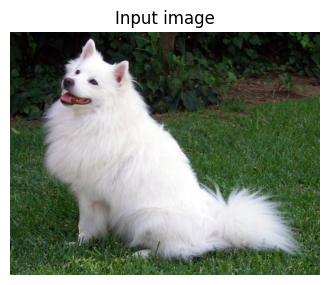

In [ ]:
IMG_PATH = "Dog.jpg"      # <- use your own path here
SAMPLE_URL = "https://github.com/pytorch/hub/raw/master/images/dog.jpg"

if not os.path.exists(IMG_PATH):
    try:
        urllib.request.urlretrieve(SAMPLE_URL, "Dog.jpg"); IMG_PATH = "Dog.jpg"
        print("Downloaded a sample image ->", IMG_PATH)
    except Exception as e:
        print("Download failed:", e)
        try:
            from google.colab import files
            up = files.upload(); IMG_PATH = next(iter(up))
        except Exception:
            raise FileNotFoundError(f"Image not found: {IMG_PATH}. Set IMG_PATH to an image on your computer.")

pil_img = Image.open(IMG_PATH).convert("RGB")
plt.figure(figsize=(4, 4)); plt.imshow(pil_img); plt.axis("off"); plt.title("Input image"); plt.show()

**Steps 3, 4 & 6 – load the pretrained models and print the top-5 predictions.** We include the tutorial's two models (VGG16, ResNet50) and the three architectures requested in the task (AlexNet, ResNet101, MobileNet).

In [ ]:
ARCHS_T6 = ["vgg16", "resnet50", "alexnet", "resnet101", "mobilenet_v2"]

def predict_top5(arch, img, topk=5, n_timing=20):
    weights = models.get_model_weights(arch).IMAGENET1K_V1
    model   = models.get_model(arch, weights=weights).eval().to(DEVICE)
    x = weights.transforms()(img).unsqueeze(0).to(DEVICE)           # load_and_preprocess_image
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]                   # make_predictions
        top_p, top_i = probs.topk(topk)
        for _ in range(3): model(x)                                 # warm-up
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n_timing): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        ms = (time.time() - t0) / n_timing * 1000
    cats = weights.meta["categories"]
    out = dict(arch=arch, top5=[(cats[i], p.item()) for p, i in zip(top_p, top_i)],
               params_M=sum(p.numel() for p in model.parameters()) / 1e6, ms=ms)
    del model
    return out

pred_results = {}
for arch in ARCHS_T6:
    r = predict_top5(arch, pil_img); pred_results[arch] = r
    print(f"\nTop 5 predictions from {arch.upper()}:")
    for i, (label, p) in enumerate(r["top5"], 1):
        print(f"{i}. {label} ({p * 100:.2f}% probability)")


Top 5 predictions from VGG16:
1. Samoyed (83.95% probability)
2. Pomeranian (3.30% probability)
3. Eskimo dog (1.68% probability)
4. white wolf (1.60% probability)
5. Great Pyrenees (1.22% probability)

Top 5 predictions from RESNET50:
1. Samoyed (87.33% probability)
2. Pomeranian (3.03% probability)
3. white wolf (1.97% probability)
4. keeshond (1.11% probability)
5. Eskimo dog (0.92% probability)

Top 5 predictions from ALEXNET:
1. Samoyed (72.45% probability)
2. wallaby (13.94% probability)
3. Pomeranian (5.87% probability)
4. Angora (2.28% probability)
5. Arctic fox (1.25% probability)

Top 5 predictions from RESNET101:
1. Samoyed (95.10% probability)
2. Pomeranian (1.91% probability)
3. white wolf (0.76% probability)
4. Eskimo dog (0.56% probability)
5. keeshond (0.36% probability)

Top 5 predictions from MOBILENET_V2:
1. Samoyed (83.03% probability)
2. Pomeranian (6.99% probability)
3. keeshond (1.30% probability)
4. collie (1.08% probability)
5. Great Pyrenees (0.99% probabilit

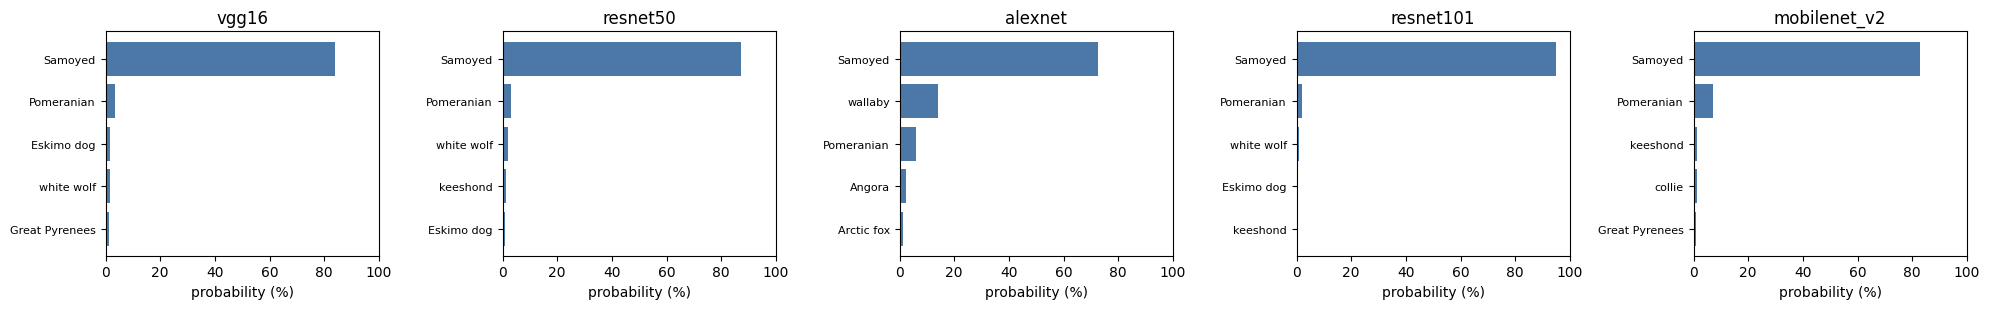

,model,top-1,top-1 prob (%),params (M),inference (cuda) ms/img
0,vgg16,Samoyed,83.95,138.4,17.9
1,resnet50,Samoyed,87.33,25.6,5.6
2,alexnet,Samoyed,72.45,61.1,3.4
3,resnet101,Samoyed,95.10,44.5,14.4
4,mobilenet_v2,Samoyed,83.03,3.5,5.8


In [ ]:
fig, axes = plt.subplots(1, len(ARCHS_T6), figsize=(4 * len(ARCHS_T6), 3.2), sharex=True)
for ax, arch in zip(axes, ARCHS_T6):
    labels, probs = zip(*pred_results[arch]["top5"])
    ax.barh(range(5)[::-1], [p * 100 for p in probs], color="#4C78A8")
    ax.set_yticks(range(5)[::-1]); ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(arch); ax.set_xlabel("probability (%)"); ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()

pd.DataFrame([{"model": a, "top-1": r["top5"][0][0], "top-1 prob (%)": round(r["top5"][0][1] * 100, 2),
               "params (M)": round(r["params_M"], 1), f"inference ({DEVICE.type}) ms/img": round(r["ms"], 1)}
              for a, r in pred_results.items()])

## Part 2 — Task: Experiment with different architectures (AlexNet, ResNet101, MobileNet)

Already covered by the loop above: same image, same pipeline, five architectures. Things to look at in the table/plots:
* **AlexNet** (2012, ~61 M params) — fastest to load, but usually less confident / less accurate.
* **ResNet101** — deeper than ResNet50, usually the most confident but slower.
* **MobileNetV2** (~3.5 M params) — tiny and fast; accuracy close to the big models → ideal for mobile / edge.
* **VGG16** — huge (138 M params, most of it in the fully-connected layers) and slow.

The next part goes beyond inference and *adapts* these architectures to a new dataset.

## Part 3 — Task: Transfer learning on a dataset (CIFAR-10) with all five architectures

For every architecture we compare **feature extraction** (only the new head trains) with **fine-tuning** (head + last 10 conv/BN layers), using the same improved recipe
(64×64, ImageNet norm, augmentation, dropout 0.3, weight decay, head LR 1e-3, backbone LR 1e-4, `EPOCHS_TL` epochs).

In [ ]:
TL_CFG = dict(img_size=IMG_SIZE_IMPROVED, norm="imagenet", augment=True, dropout=0.3, weight_decay=1e-2,
              epochs=EPOCHS_TL, lr_head=1e-3, lr_backbone=1e-4, unfreeze=10)
tl_results = []
for arch in ARCHS_T6:
    for mode in ("fe", "ft"):
        tl_results.append(run_experiment(f"TL {arch} {mode.upper()}", arch, mode, **TL_CFG))


=== TL vgg16 FE  [vgg16 | fe | 64px | unfreeze=- | lr 0.001/0.0001 | epochs 5]
  epoch  1/5  train loss 0.984 acc 0.656 | val loss 0.767 acc 0.729 | 27s
  epoch  2/5  train loss 0.844 acc 0.702 | val loss 0.755 acc 0.734 | 27s
  epoch  3/5  train loss 0.810 acc 0.713 | val loss 0.713 acc 0.756 | 26s
  epoch  4/5  train loss 0.787 acc 0.720 | val loss 0.711 acc 0.756 | 26s
  epoch  5/5  train loss 0.767 acc 0.729 | val loss 0.679 acc 0.763 | 27s
  >> TL vgg16 FE Test Accuracy: 76.11%  (trainable params 267,786, 133s)

=== TL vgg16 FT  [vgg16 | ft | 64px | unfreeze=10 | lr 0.001/0.0001 | epochs 5]
  epoch  1/5  train loss 0.495 acc 0.832 | val loss 0.316 acc 0.886 | 33s
  epoch  2/5  train loss 0.283 acc 0.906 | val loss 0.293 acc 0.899 | 33s
  epoch  3/5  train loss 0.222 acc 0.926 | val loss 0.227 acc 0.924 | 33s
  epoch  4/5  train loss 0.174 acc 0.941 | val loss 0.207 acc 0.930 | 33s
  epoch  5/5  train loss 0.151 acc 0.949 | val loss 0.254 acc 0.920 | 33s
  >> TL vgg16 FT Test Accu

Test accuracy (%) on CIFAR-10


mode,Feature extraction,Fine-tuning
arch,,
vgg16,76.11,91.65
resnet50,76.18,83.28
alexnet,62.71,80.68
resnet101,74.86,80.87
mobilenet_v2,69.66,77.58


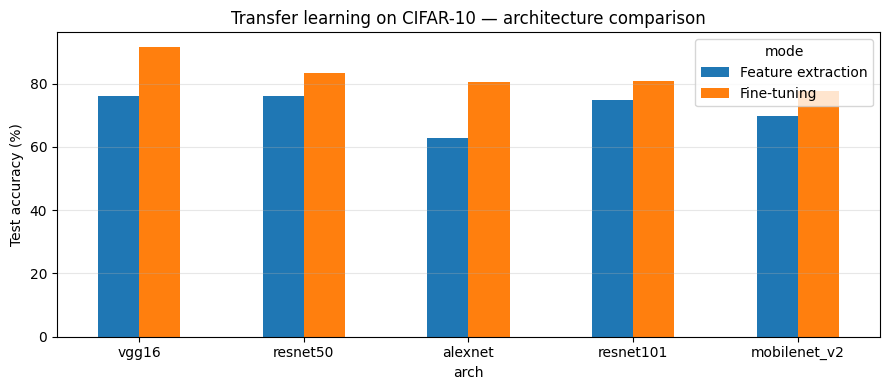

,name,trainable_params,train_time_s,best_val_acc,test_acc
0,TL vgg16 FE,267786,133,76.32,76.11
1,TL vgg16 FT,14869898,164,93.00,91.65
2,TL resnet50 FE,1054218,155,77.30,76.18
3,TL resnet50 FT,8929802,174,83.96,83.28
4,TL alexnet FE,136714,132,62.96,62.71
5,TL alexnet FT,2606410,137,80.68,80.68
6,TL resnet101 FE,1054218,198,76.60,74.86
7,TL resnet101 FT,8929802,207,83.08,80.87
8,TL mobilenet_v2 FE,661002,162,71.38,69.66
9,TL mobilenet_v2 FT,1701002,167,79.28,77.58


In [ ]:
df = results_table(tl_results)
pivot = df.pivot(index="arch", columns="mode", values="test_acc").rename(columns={"fe": "Feature extraction", "ft": "Fine-tuning"})
pivot = pivot.loc[ARCHS_T6]
print("Test accuracy (%) on CIFAR-10"); display(pivot)
pivot.plot(kind="bar", figsize=(9, 4), rot=0); plt.ylabel("Test accuracy (%)"); plt.grid(axis="y", alpha=.3)
plt.title("Transfer learning on CIFAR-10 — architecture comparison"); plt.tight_layout(); plt.show()
display(df[["name", "trainable_params", "train_time_s", "best_val_acc", "test_acc"]])

## Part 4 — Final comparison of every experiment

,name,mode,img_size,trainable_params,test_acc,train_time_s
0,TL vgg16 FT,ft,64,14869898,91.65,164
1,TL resnet50 FT,ft,64,8929802,83.28,174
2,TL resnet101 FT,ft,64,8929802,80.87,207
3,TL alexnet FT,ft,64,2606410,80.68,137
4,TL mobilenet_v2 FT,ft,64,1701002,77.58,167
5,TL resnet50 FE,fe,64,1054218,76.18,155
6,TL vgg16 FE,fe,64,267786,76.11,133
7,TL resnet101 FE,fe,64,1054218,74.86,198
8,TL mobilenet_v2 FE,fe,64,661002,69.66,162
9,TL alexnet FE,fe,64,136714,62.71,132


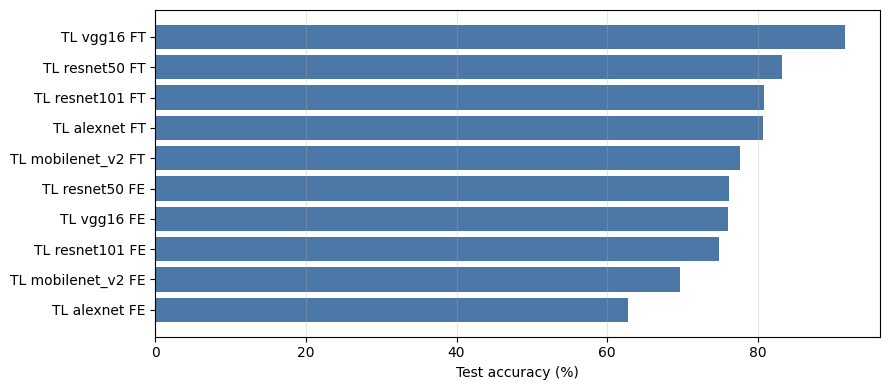

Best model: TL vgg16 FT -> 91.65%


In [ ]:
final = results_table(RESULTS).sort_values("test_acc", ascending=False).reset_index(drop=True)
display(final[["name", "mode", "img_size", "trainable_params", "test_acc", "train_time_s"]])
final.to_csv("transfer_learning_results.csv", index=False)

plt.figure(figsize=(9, max(4, 0.32 * len(final))))
plt.barh(final["name"][::-1], final["test_acc"][::-1], color="#4C78A8")
plt.xlabel("Test accuracy (%)"); plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()
print("Best model:", BEST["name"], f"-> {BEST['acc'] * 100:.2f}%")

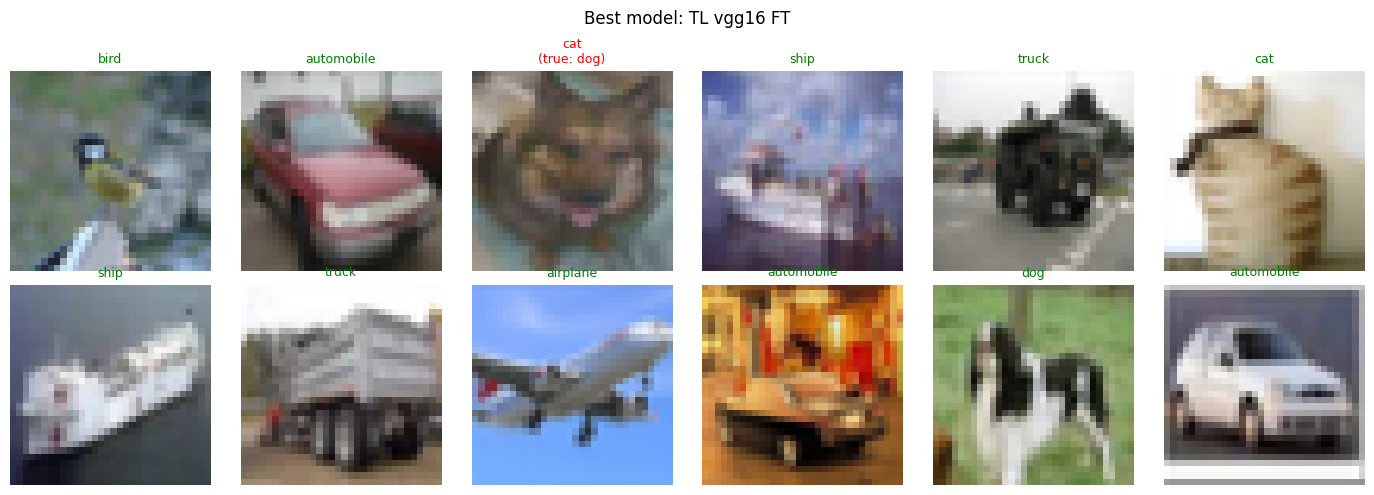

saved best_model.pt


In [ ]:
# Predictions of the best model on a few test images
cfg, model = BEST["cfg"], BEST["model"].to(DEVICE).eval()
raw_test = datasets.CIFAR10(DATA_DIR, train=False, download=False)
_, ev_t = make_transforms(cfg["img_size"], cfg["norm"], False)
idxs = TEST_IDX[:12]
x = torch.stack([ev_t(raw_test[i][0]) for i in idxs]).to(DEVICE)
with torch.no_grad(): pred = model(x).argmax(1).cpu().numpy()
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i, p in zip(axes.ravel(), idxs, pred):
    img, y = raw_test[i]; ax.imshow(img); ax.axis("off")
    ax.set_title(f"{CLASSES[p]}" + ("" if p == y else f"\n(true: {CLASSES[y]})"), color="green" if p == y else "red", fontsize=9)
plt.suptitle(f"Best model: {BEST['name']}"); plt.tight_layout(); plt.show()

torch.save(model.state_dict(), "best_model.pt"); print("saved best_model.pt")

## Conclusions (compare with *your* numbers above)

**Pretrained inference.** All five models were trained on ImageNet (1000 classes), so they work out of the box on everyday photos; each torchvision weight set carries its own preprocessing and class names.

**Architectures.** Bigger/deeper nets (ResNet101, ResNet50, VGG16) are usually more accurate and more confident but slower; MobileNetV2 is tiny (~3.5 M params) and fast with accuracy close to the big models; AlexNet is the oldest and weakest. VGG16 is by far the heaviest in parameters (138 M, mostly in its fully-connected layers).

**Transfer learning on a new dataset.** Feature extraction is cheap and gives a strong baseline; fine-tuning the last layers with a small backbone learning rate usually improves it, at the cost of more training time. Use the table in Part 3 to pick the best accuracy/speed trade-off.